# Importing Necessary Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm

# Data Loading and Data Cleaning

**Loading the raw datasets**

In [2]:
df_iip_70 = pd.read_excel("iip_70.xlsx")
df_iip_72 = pd.read_excel("iip_72.xlsx")
df_merc_usd = pd.read_excel("Merc_trade_USD.xlsx")
df_non_food = pd.read_csv("non_food.csv")
df_GDP = pd.read_csv("qtr_gdp_mrkt_prc_rn.csv")

/Users/debodirnoghosh/anaconda3/lib/python3.10/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


**Initial formatting of IIP, Merchandise Exports, and Non-Food Bank Credit**

In [3]:
df_iip_combo = pd.concat([df_iip_72,df_iip_70],ignore_index = True)
df_iip_combo["Date"] = pd.to_datetime(df_iip_combo["year"].astype(str) + "-" + df_iip_combo["month"], format= "%Y-%B")
df_iip_combo = df_iip_combo.sort_values("Date").reset_index(drop=True)

df_exports = df_merc_usd.iloc[7:-2,1:5].copy()
df_exports.columns = ["FY","Month","Export_oil_USD","Export_non_oil_USD"]
df_exports["Export_oil_USD"] = pd.to_numeric(df_exports["Export_oil_USD"])
df_exports["Export_non_oil_USD"]= pd.to_numeric(df_exports["Export_non_oil_USD"])
df_exports["Total_export"] = df_exports["Export_oil_USD"] + df_exports["Export_non_oil_USD"]

df_NFC = df_non_food.iloc[7:-3].copy()
df_credit = df_NFC.iloc[:,4:].copy()
df_credit.columns = ["Date","Total_Credit","Food_Credit","Non_Food_Credit"]
df_credit["Date"] = pd.to_datetime(df_credit["Date"].str.strip(), format = "%b %d, %Y")
df_credit["Non_Food_Credit"] = pd.to_numeric(
    df_credit["Non_Food_Credit"].astype(str).str.replace(",", ""), 
    errors="coerce"
)

**We now append the base year (2011-12) index for the IIP data and compute quarterly average and YoY growth for IIP**

In [4]:
base_dates = pd.date_range(start="2011-04-01",end="2012-03-01",freq="MS")
df_iip_base = pd.DataFrame({"Date":base_dates,"index":100.0})
df_iip_full = pd.concat([df_iip_base,df_iip_combo[["Date","index"]]],ignore_index = True)
df_iip_full = df_iip_full.sort_values("Date").reset_index(drop=True)

df_iip_full["qtr_end"] = df_iip_full["Date"].dt.to_period("Q").dt.end_time.dt.normalize()

#Group by quarters
df_iip_qtr = df_iip_full.groupby("qtr_end")["index"].mean().reset_index()
df_iip_qtr = df_iip_qtr.rename(columns={"qtr_end":"Date","index":"IIP_QTR_Avg"})

#Computing YoY growth for IIP
df_iip_qtr["IIP_growth"] = (df_iip_qtr["IIP_QTR_Avg"]/df_iip_qtr["IIP_QTR_Avg"].shift(4)- 1.0)*100.0

**Data Cleaning of GDP and YoY growth**

In [5]:
df_gdp_clean = df_GDP[["time_period","obs_value"]].copy()
df_gdp_clean = df_gdp_clean.rename(columns={"time_period":"Date","obs_value":"GDP_real"})
df_gdp_clean["Date"] = pd.to_datetime(df_gdp_clean["Date"])
df_gdp_clean = df_gdp_clean.sort_values("Date").reset_index(drop=True)
df_gdp_clean["GDP_growth"]= (df_gdp_clean["GDP_real"]/df_gdp_clean["GDP_real"].shift(4)- 1.0)*100.0

**Data Cleaning and Quarterly average and YoY growth for Merchandise Exports in USD**

In [6]:
month_num = pd.to_datetime(df_exports["Month"].str.strip(), format="%B").dt.month
start_year = df_exports["FY"].str.slice(0,4).astype(int)
cal_year = start_year + (month_num < 4).astype(int)
df_exports["Date"] = pd.to_datetime(cal_year.astype(str) + "-" + month_num.astype(str) + "-01")
df_exports = df_exports.sort_values("Date").reset_index(drop=True)

df_export_clean = df_exports[["Date","Total_export"]].copy()
df_export_clean = df_export_clean.rename(columns={"Total_export":"Merc_export"})
df_export_clean["qtr_end"] = df_export_clean["Date"].dt.to_period("Q").dt.end_time.dt.normalize()
df_export_qtr = df_export_clean.groupby("qtr_end")["Merc_export"].mean().reset_index()
df_export_qtr = df_export_qtr.rename(columns={"qtr_end":"Date","Merc_export":"Merc_QTR_Avg"})

#Measuring the YoY growth for the Merchandise exports
df_export_qtr["Export_growth"]= (df_export_qtr["Merc_QTR_Avg"]/df_export_qtr["Merc_QTR_Avg"].shift(4)- 1.0)*100.0

**Data Cleaning and measuring the quarterly avg, YoY growth of the Non-Food Credits of Bank**

In [7]:
df_non_food = df_credit[df_credit["Non_Food_Credit"] > 0][["Date", "Non_Food_Credit"]].copy()
df_non_food["qtr_end"] = df_non_food["Date"].dt.to_period("Q").dt.end_time.dt.normalize()

df_NF_qtr = df_non_food.groupby("qtr_end")["Non_Food_Credit"].mean().reset_index()
df_NF_qtr = df_NF_qtr.rename(columns={"qtr_end": "Date", "Non_Food_Credit": "NF_Credit_Avg"})
df_NF_qtr["NF_Credit_growth"] = (df_NF_qtr["NF_Credit_Avg"] / df_NF_qtr["NF_Credit_Avg"].shift(4) - 1.0) * 100.0

**We take all the datasets as a subset of a larger dataset so that we can treat them on equal footing**

In [8]:
gdp_sub = df_gdp_clean[["Date","GDP_growth"]].copy()
iip_sub = df_iip_qtr[["Date","IIP_growth"]].copy()
exp_sub = df_export_qtr[["Date","Export_growth"]].copy()
cred_sub =df_NF_qtr[["Date","NF_Credit_growth"]].copy()

# Merging all the datasets to make a larger set as IIP dataset as backbone
df_all = gdp_sub.merge(iip_sub, on="Date",how ="right")\
                .merge(exp_sub, on="Date",how ="left")\
                .merge(cred_sub, on="Date",how ="left")

# We now filter the combined dataset to start from Q1 FY2012-13 (2012-06-30) and end at Q4 FY2025-26 (2026-03-31).

df_extended = df_all[(df_all["Date"] >="2012-06-30")&(df_all["Date"]<= "2026-03-31")].reset_index(drop=True)
df_project = df_extended[df_extended["Date"] <= "2025-09-30"].copy().reset_index(drop=True)
print("Official Project Dataset (up to Sep 2025):", df_project.shape)

Official Project Dataset (up to Sep 2025): (54, 5)


# Naive Benchmark, Train-Test Split, and OLS Regression Modeling

**Next we set up the naive benchmark to assume the current quarter's growth to be equal to the last quarter's growth and then split the data into training and test data**

In [9]:
df_project["Naive_pred"] = df_project["GDP_growth"].shift(1)

#We do the train-test split now

train_df = df_project[(df_project["Date"]>= "2012-06-30") & (df_project["Date"]<="2020-03-31")].copy()
test_df = df_project[(df_project["Date"]>= "2022-06-30") & (df_project["Date"]<="2025-09-30")].copy()
print(f"Training quarters: {len(train_df)} | Test quarters: {len(test_df)}")

Training quarters: 32 | Test quarters: 14


**Estimating OLS Regressions on training data set**

In [10]:
y_train = train_df["GDP_growth"]

x_train_iip = sm.add_constant(train_df[["IIP_growth"]])
reg_model_iip = sm.OLS(y_train,x_train_iip).fit()

x_train_exp = sm.add_constant(train_df[["Export_growth"]])
reg_model_exp = sm.OLS(y_train,x_train_exp).fit()

x_train_cred = sm.add_constant(train_df[["NF_Credit_growth"]])
reg_model_cred = sm.OLS(y_train,x_train_cred).fit()

x_train_all = sm.add_constant(train_df[["IIP_growth","Export_growth","NF_Credit_growth"]])
reg_model_all = sm.OLS(y_train,x_train_all).fit()

print(reg_model_iip.summary())
print(reg_model_exp.summary())
print(reg_model_cred.summary())
print(reg_model_all.summary())

# Store the fitted values from each OLS model inside train_df
train_df["Fit_IIP"] = reg_model_iip.fittedvalues
train_df["Fit_Exp"] = reg_model_exp.fittedvalues
train_df["Fit_Crd"] = reg_model_cred.fittedvalues
train_df["Fit_All"] = reg_model_all.fittedvalues

                            OLS Regression Results                            
Dep. Variable:             GDP_growth   R-squared:                       0.299
Model:                            OLS   Adj. R-squared:                  0.276
Method:                 Least Squares   F-statistic:                     12.80
Date:                Wed, 18 Nov 2026   Prob (F-statistic):            0.00120
Time:                        17:00:19   Log-Likelihood:                -55.985
No. Observations:                  32   AIC:                             116.0
Df Residuals:                      30   BIC:                             118.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.4057      0.419     12.903      0.0

**Predict Test Quarters and Build the Error Table (MAE and RMSE)**

In [11]:
test_df["Pred_IIP"] = reg_model_iip.predict(sm.add_constant(test_df[["IIP_growth"]],has_constant ="add"))
test_df["Pred_Export"] = reg_model_exp.predict(sm.add_constant(test_df[["Export_growth"]],has_constant ="add"))
test_df["Pred_Credit"] = reg_model_cred.predict(sm.add_constant(test_df[["NF_Credit_growth"]],has_constant ="add"))
test_df["Pred_Multiple"] = reg_model_all.predict(sm.add_constant(test_df[["IIP_growth","Export_growth","NF_Credit_growth"]],has_constant ="add"))

models_to_eval = [
    ("Naive Benchmark (Last Qtr Growth)", "Naive_pred"),
    ("Single OLS: IIP General Index", "Pred_IIP"),
    ("Single OLS: Merchandise Exports", "Pred_Export"),
    ("Single OLS: Non-Food Bank Credit", "Pred_Credit"),
    ("Multiple OLS: All 3 Indicators", "Pred_Multiple")
]
error_rows = []
for name, col in models_to_eval:
    errors = test_df["GDP_growth"] - test_df[col]
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))
    error_rows.append({"Model": name, "MAE (%)": round(mae, 4), "RMSE (%)": round(rmse, 4)})

df_error_table = pd.DataFrame(error_rows)
print(df_error_table.to_string(index = False))

                            Model  MAE (%)  RMSE (%)
Naive Benchmark (Last Qtr Growth)   2.1077    3.3717
    Single OLS: IIP General Index   1.2462    1.5309
  Single OLS: Merchandise Exports   1.7859    2.4773
 Single OLS: Non-Food Bank Credit   1.8214    2.5124
   Multiple OLS: All 3 Indicators   1.2627    1.6002


# Plotting the Results

**Plotting each indicator against the GDP growth**

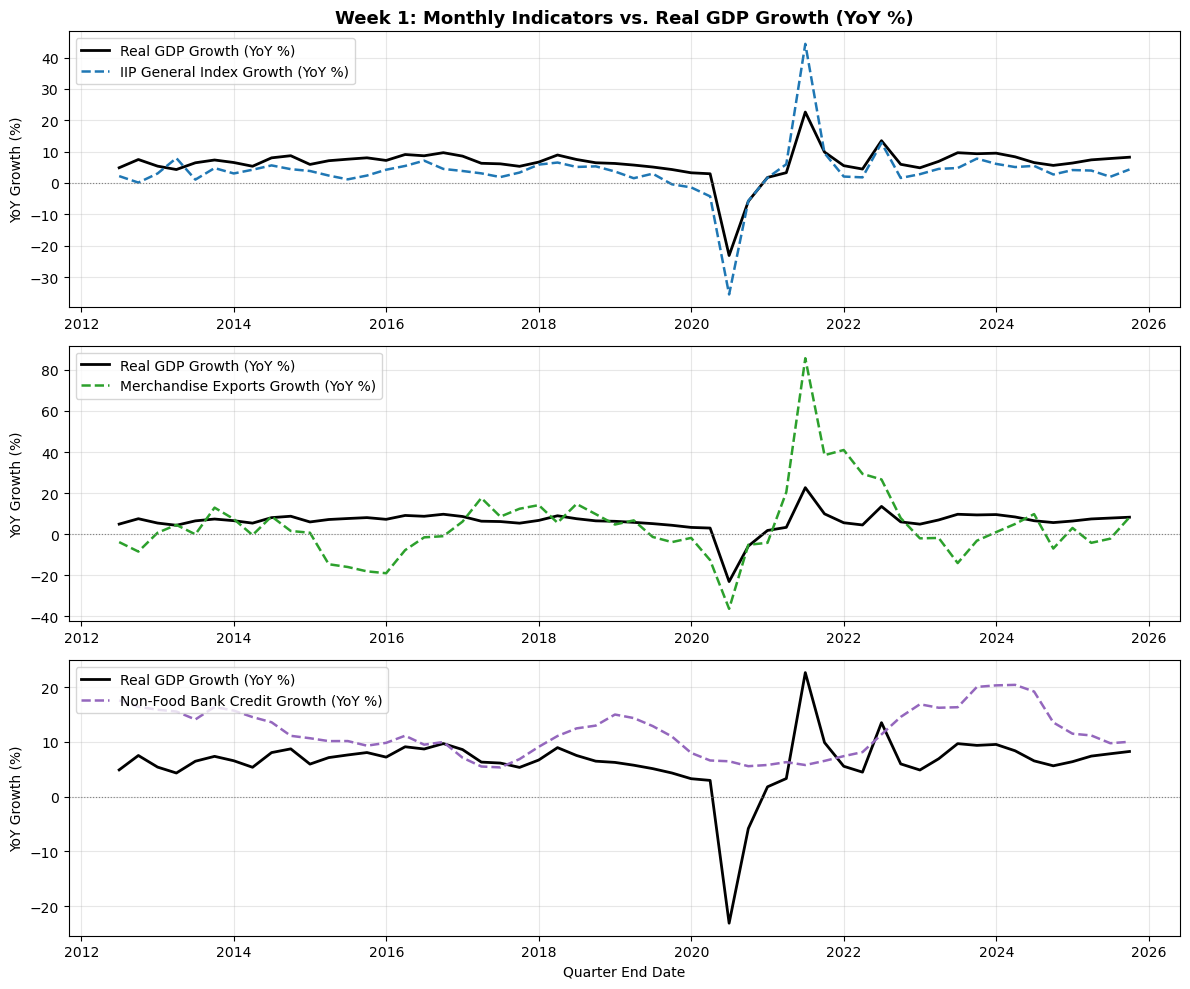

In [12]:
plt.figure(figsize=(12, 10))

indicators = [
    ("IIP_growth", "IIP General Index Growth (YoY %)", "tab:blue"),
    ("Export_growth", "Merchandise Exports Growth (YoY %)", "tab:green"),
    ("NF_Credit_growth", "Non-Food Bank Credit Growth (YoY %)", "tab:purple")
]

for i, (col, label, color) in enumerate(indicators, start=1):
    plt.subplot(3, 1, i)  # Select subplot 1, 2, or 3
    
    plt.plot(df_project["Date"], df_project["GDP_growth"], label="Real GDP Growth (YoY %)", color="black", linewidth=2)
    plt.plot(df_project["Date"], df_project[col], label=label, color=color, linestyle="--", linewidth=1.8)
    plt.axhline(0, color="gray", linewidth=0.8, linestyle=":")
    
    plt.ylabel("YoY Growth (%)")
    plt.legend(loc="upper left")
    plt.grid(True, alpha=0.3)
    
    if i == 1:
        plt.title("Week 1: Monthly Indicators vs. Real GDP Growth (YoY %)", fontsize=13, fontweight="bold")

plt.xlabel("Quarter End Date")
plt.tight_layout()
plt.show()

**Plotting the regression models on the training period**

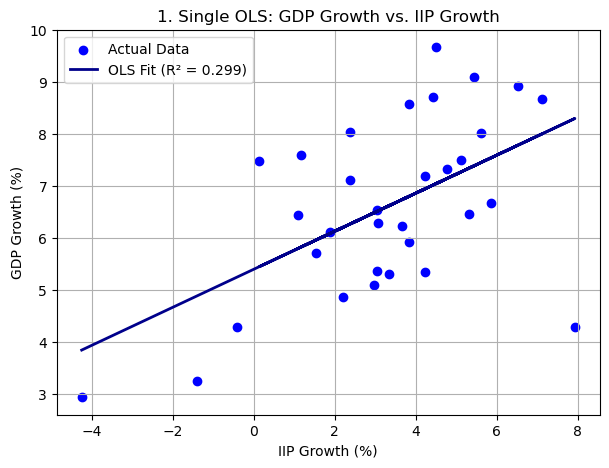

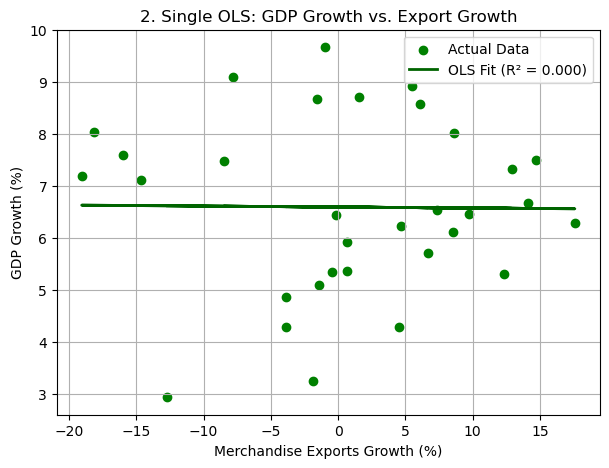

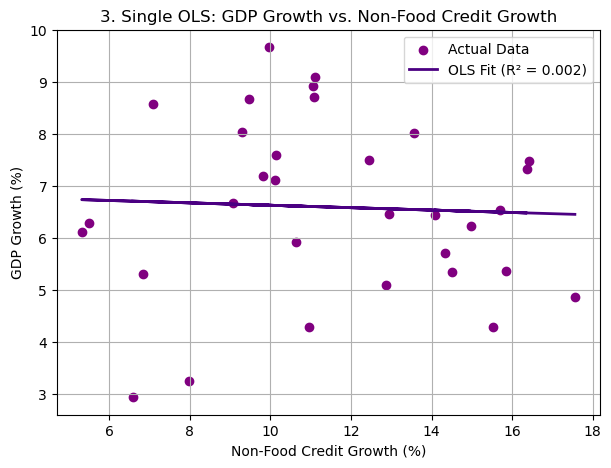

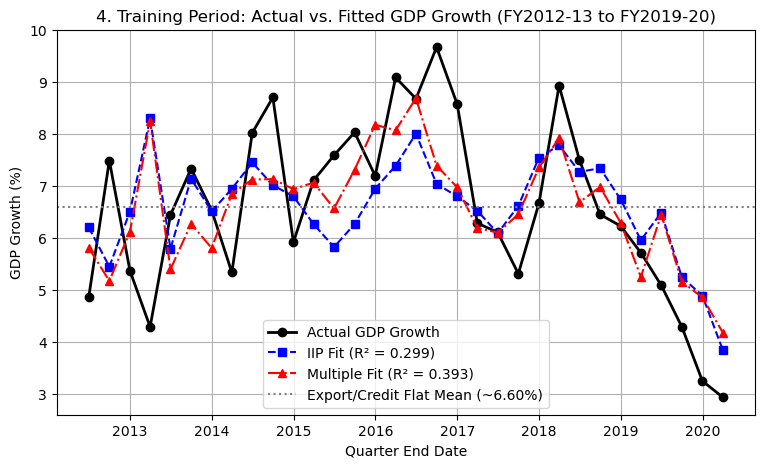

In [13]:
# --- Plot 1: IIP Single Regression ---
plt.figure(figsize=(7, 5))
plt.scatter(train_df["IIP_growth"], train_df["GDP_growth"], color="blue", label="Actual Data")
plt.plot(train_df["IIP_growth"], train_df["Fit_IIP"], color="darkblue", linewidth=2, label="OLS Fit (R² = 0.299)")
plt.title("1. Single OLS: GDP Growth vs. IIP Growth")
plt.xlabel("IIP Growth (%)")
plt.ylabel("GDP Growth (%)")
plt.legend()
plt.grid(True)
plt.show()

# --- Plot 2: Merchandise Exports Single Regression ---
plt.figure(figsize=(7, 5))
plt.scatter(train_df["Export_growth"], train_df["GDP_growth"], color="green", label="Actual Data")
plt.plot(train_df["Export_growth"], train_df["Fit_Exp"], color="darkgreen", linewidth=2, label="OLS Fit (R² = 0.000)")
plt.title("2. Single OLS: GDP Growth vs. Export Growth")
plt.xlabel("Merchandise Exports Growth (%)")
plt.ylabel("GDP Growth (%)")
plt.legend()
plt.grid(True)
plt.show()

# --- Plot 3: Non-Food Credit Single Regression ---
plt.figure(figsize=(7, 5))
plt.scatter(train_df["NF_Credit_growth"], train_df["GDP_growth"], color="purple", label="Actual Data")
plt.plot(train_df["NF_Credit_growth"], train_df["Fit_Crd"], color="indigo", linewidth=2, label="OLS Fit (R² = 0.002)")
plt.title("3. Single OLS: GDP Growth vs. Non-Food Credit Growth")
plt.xlabel("Non-Food Credit Growth (%)")
plt.ylabel("GDP Growth (%)")
plt.legend()
plt.grid(True)
plt.show()

# --- Plot 4: Time-Series Comparison (Actual vs Fitted over Time) ---
plt.figure(figsize=(9, 5))
plt.plot(train_df["Date"], train_df["GDP_growth"], color="black", marker="o", linewidth=2, label="Actual GDP Growth")
plt.plot(train_df["Date"], train_df["Fit_IIP"], color="blue", linestyle="--", marker="s", label="IIP Fit (R² = 0.299)")
plt.plot(train_df["Date"], train_df["Fit_All"], color="red", linestyle="-.", marker="^", label="Multiple Fit (R² = 0.393)")
plt.axhline(train_df["GDP_growth"].mean(), color="gray", linestyle=":", label="Export/Credit Flat Mean (~6.60%)")
plt.title("4. Training Period: Actual vs. Fitted GDP Growth (FY2012-13 to FY2019-20)")
plt.xlabel("Quarter End Date")
plt.ylabel("GDP Growth (%)")
plt.legend()
plt.grid(True)
plt.show()

**Plotting Actual vs. Predicted Real GDP Growth on the Test Period**

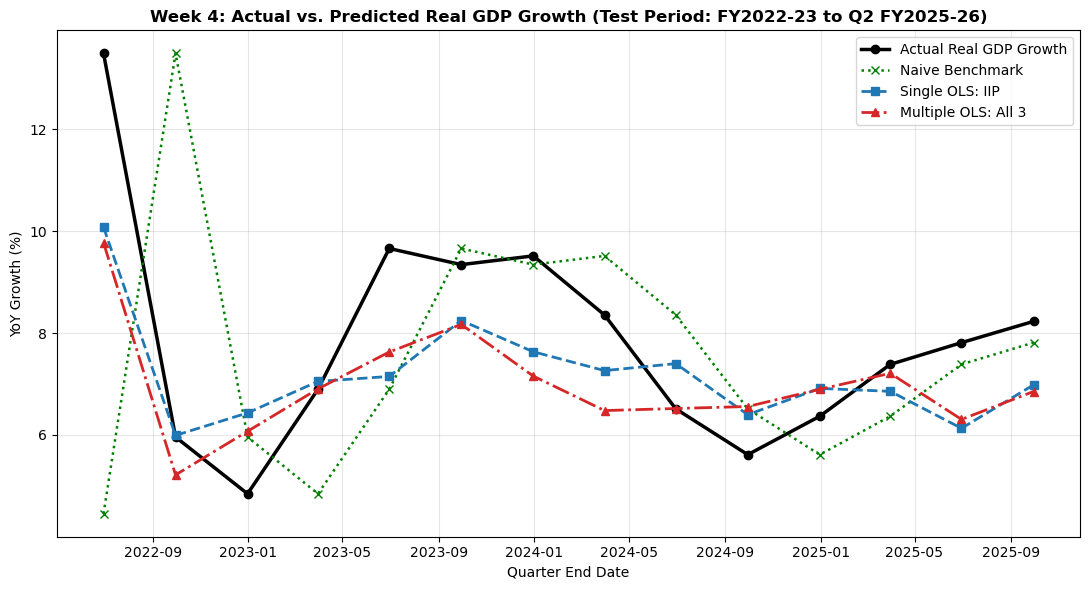

In [14]:
plt.figure(figsize=(11, 6))
plt.plot(test_df["Date"], test_df["GDP_growth"], label="Actual Real GDP Growth", color="black", linewidth=2.5, marker="o")
plt.plot(test_df["Date"], test_df["Naive_pred"], label="Naive Benchmark", color="green", linestyle=":", linewidth=1.8, marker="x")
plt.plot(test_df["Date"], test_df["Pred_IIP"], label="Single OLS: IIP", color="tab:blue", linestyle="--", linewidth=2, marker="s")
plt.plot(test_df["Date"], test_df["Pred_Multiple"], label="Multiple OLS: All 3", color="tab:red", linestyle="-.", linewidth=2, marker="^")

plt.title("Week 4: Actual vs. Predicted Real GDP Growth (Test Period: FY2022-23 to Q2 FY2025-26)", fontsize=12, fontweight="bold")
plt.xlabel("Quarter End Date")
plt.ylabel("YoY Growth (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Extracting the Cleaned Dataset in Excel Format

In [15]:
df_NF_qtr = df_NF_qtr.rename(columns={"Non_Food_Credit":"Non_Food_Credit_QTR_Avg in Crore rupees","NF_Credit_growth":"Non_Food_Credit YoY growth in percentage" })
df_export_qtr = df_export_qtr.rename(columns={"Merc_QTR_Avg":"Total_Merchandise_Export_QTR_Avg in dollars","Export_growth":"Total_Merchandise_Export YoY growth in percentage" })
df_gdp_clean = df_gdp_clean.rename(columns={"GDP_growth":"GDP YoY growth in percentage"})
df_iip_qtr = df_iip_qtr.rename(columns={"IIP_growth":"IIP YoY growth in percentage"})

# 1. Export the 4 individual cleaned quarterly datasets (trimmed from Q1 FY2012-13 onwards)
df_gdp_clean[df_gdp_clean["Date"] >= "2012-06-30"].assign(
    Date=lambda x: x["Date"].dt.strftime("%Y-%m-%d")
).to_excel("GDP_quarterly_cleaned.xlsx", index=False)

df_iip_qtr[df_iip_qtr["Date"] >= "2012-06-30"].assign(
    Date=lambda x: x["Date"].dt.strftime("%Y-%m-%d")
).to_excel("IIP_quarterly_cleaned.xlsx", index=False)

df_export_qtr[df_export_qtr["Date"] >= "2012-06-30"].assign(
    Date=lambda x: x["Date"].dt.strftime("%Y-%m-%d")
).to_excel("Exports_quarterly_cleaned.xlsx", index=False)

df_NF_qtr[df_NF_qtr["Date"] >= "2012-06-30"].assign(
    Date=lambda x: x["Date"].dt.strftime("%Y-%m-%d")
).to_excel("NonFoodCredit_quarterly_cleaned.xlsx", index=False)

# 2. Also export the single merged Master Dataset (all 4 series aligned in one table)
df_project.assign(
    Date=lambda x: x["Date"].dt.strftime("%Y-%m-%d")
).to_excel("Master_GDP_Indicators_Cleaned.xlsx", index=False)

print("All cleaned Excel files have been saved successfully with valid dates!")

All cleaned Excel files have been saved successfully with valid dates!
